# 03 — Phase 4: Temporal Fire-Spread Tensor Export (Colab)

**Student 4 — Task 1 / Phase 4 (temporal pipeline)**

This notebook reads the aligned GeoTIFFs from Google Drive and builds
**temporal sliding-window samples** for daily fire-spread prediction.

## What this notebook does
1. Mounts Google Drive and installs packages
2. Sets Drive paths and output directories
3. Merges `fire_mask_update/` → `aligned_compressed/` (adds daily fire masks)
4. Discovers ready fires and loads event-level train / val / test splits
5. For every ready fire, creates sliding-window samples
   - **X**: `WINDOW_SIZE` days of fire mask + weather + static terrain
   - **Y**: fire mask at day t+1 (the model's prediction target)
6. Saves samples to `tensors/train/`, `tensors/val/`, `tensors/test/`
7. Writes `sample_index.csv` and `tensor_manifest.json`

## Before you start
- Student 3's `aligned_compressed/` must be on the shared Google Drive.
- The `fire_mask_update/aligned_compressed/` folder must also be on Drive.
- **You only need to edit three values in Step 2.**

---
### Temporal sample layout — each `sample_NNNNNN.npz` contains

| Key | Shape | dtype | Content |
|-----|-------|-------|---------|
| `fire_masks` | `(W, H, Wpx)` | uint8 | daily fire mask, days t−W+1 … t |
| `weather` | `(W, 6, H, Wpx)` | float32 | ERA5 weather (6 vars), days t−W+1 … t |
| `terrain` | `(3, H, Wpx)` | float32 | static elevation, slope, aspect |
| `Y` | `(H, Wpx)` | uint8 | fire mask at day t+1 — **prediction target** |

A fire with **N** daily bands produces **N − W** samples (W = window size, default 4).

---
## Step 1 — Mount Google Drive and install packages

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# rasterio is not pre-installed in Colab — install it once per session
!pip install rasterio -q
print('Packages ready.')

Packages ready.


---
## Step 2 — Set your Google Drive paths

**This is the only cell you need to edit.**

Set `ALIGNED_DIR` to the folder where `aligned_compressed/` lives in your Drive.
If the folder is `My Drive/wildfire_project/data/aligned_compressed`, then set:
```python
ALIGNED_DIR = '/content/drive/MyDrive/wildfire_project/data/aligned_compressed'
```

In [3]:
from pathlib import Path

# ── EDIT THESE THREE VALUES ─────────────────────────────────────────────────
# Where Student 3's aligned_compressed/ lives on your Drive
ALIGNED_DIR = Path('/content/drive/MyDrive/bigdata/Dataset/aligned_compressed')

# Where fire_mask_update/aligned_compressed/ lives on your Drive
FIRE_MASK_UPDATE_DIR = Path('/content/drive/MyDrive/bigdata/Dataset/fire_mask_update/aligned_compressed')

# Days of history as model input (default 4: days t-3, t-2, t-1, t → predict t+1)
WINDOW_SIZE = 4
# ────────────────────────────────────────────────────────────────────────────

DRIVE_DATA = ALIGNED_DIR.parent
TENSOR_DIR = DRIVE_DATA / 'tensors'
SPLITS_DIR = DRIVE_DATA / 'splits'
REPORT_CSV = ALIGNED_DIR / 'compression_report.csv'

# Create output split subdirectories up front
for split in ('train', 'val', 'test'):
    (TENSOR_DIR / split).mkdir(parents=True, exist_ok=True)

print('aligned_compressed   :', ALIGNED_DIR)
print('  exists             :', ALIGNED_DIR.exists())
print('fire_mask_update     :', FIRE_MASK_UPDATE_DIR)
print('  exists             :', FIRE_MASK_UPDATE_DIR.exists())
print('tensors output       :', TENSOR_DIR)
print('splits dir           :', SPLITS_DIR)
print('window size          :', WINDOW_SIZE, 'days')

aligned_compressed   : /content/drive/MyDrive/bigdata/Dataset/aligned_compressed
  exists             : True
fire_mask_update     : /content/drive/MyDrive/bigdata/Dataset/fire_mask_update/aligned_compressed
  exists             : True
tensors output       : /content/drive/MyDrive/bigdata/Dataset/tensors
splits dir           : /content/drive/MyDrive/bigdata/Dataset/splits
window size          : 4 days


---
## Step 3 — Merge fire_mask_update into aligned_compressed

Copies `fire_mask_stacked_30m_aligned.tif` from the update folder into
each fire's `labels/` directory so the temporal pipeline can find it.

Safe to re-run — existing files are never overwritten.

In [4]:
import shutil

FIRE_MASK_FILENAME = 'fire_mask_stacked_30m_aligned.tif'
merged, already_there, not_in_update = [], [], []

if not FIRE_MASK_UPDATE_DIR.exists():
    print(f'WARNING: FIRE_MASK_UPDATE_DIR not found:\n  {FIRE_MASK_UPDATE_DIR}')
    print('Skipping merge — only fires that already have fire_mask_stacked will be built.')
else:
    for fire_dir in sorted(ALIGNED_DIR.iterdir()):
        if not fire_dir.is_dir():
            continue
        fire_id = fire_dir.name
        dest = fire_dir / 'labels' / FIRE_MASK_FILENAME
        src  = FIRE_MASK_UPDATE_DIR / fire_id / 'labels' / FIRE_MASK_FILENAME

        if dest.exists():
            already_there.append(fire_id)
        elif src.exists():
            shutil.copy2(src, dest)
            merged.append(fire_id)
        else:
            not_in_update.append(fire_id)

    print(f'Merged  : {len(merged):3d} fires  (fire_mask_stacked copied)')
    print(f'Present : {len(already_there):3d} fires  (already existed — skipped)')
    print(f'Missing : {len(not_in_update):3d} fires  (not in fire_mask_update/)')
    if not_in_update:
        print('  These fires will be skipped during tensor build:')
        for fid in not_in_update[:5]:
            print(f'    {fid}')

Merged  :   0 fires  (fire_mask_stacked copied)
Present : 138 fires  (already existed — skipped)
Missing :   0 fires  (not in fire_mask_update/)


In [5]:
import csv, json
import numpy as np

# ── Discover which fires have all required files ───────────────────────────
# Scans aligned_compressed/ directly — does NOT filter by compression_report.csv
# fire_complete flag, which may be stale or only cover a subset of fires.

REQUIRED_LAYERS = [
    'labels/fire_mask_stacked_30m_aligned.tif',
    'labels/severity_30m_aligned.tif',
    'terrain/terrain_30m_aligned.tif',
    'weather/weather_stacked_30m_aligned.tif',
]

fire_ids = []
skipped  = []

all_dirs = sorted([d for d in ALIGNED_DIR.iterdir() if d.is_dir()])
print(f'Fire folders found in aligned_compressed/ : {len(all_dirs)}')

for fire_dir in all_dirs:
    fid     = fire_dir.name
    missing = [l for l in REQUIRED_LAYERS if not (fire_dir / l).exists()]
    if missing:
        skipped.append((fid, missing[0]))
    else:
        fire_ids.append(fid)

print(f'Ready for temporal pipeline : {len(fire_ids)} fires  (all 4 required files present)')
print(f'Skipped (missing files)     : {len(skipped)} fires')
if skipped:
    print('  First missing file per skipped fire (first 5):')
    for fid, m in skipped[:5]:
        print(f'    {fid}: {m}')

# ── Load or regenerate event-level splits ─────────────────────────────────
TRAIN_FRAC, VAL_FRAC, TEST_FRAC, SEED = 0.70, 0.15, 0.15, 42

splits_json_path = SPLITS_DIR / 'splits.json'
if splits_json_path.exists():
    with open(splits_json_path) as f:
        _sd = json.load(f)
    split_map = {}
    for s in ('train', 'val', 'test'):
        for fid in _sd.get(s, []):
            split_map[fid] = s
    # Fires found on Drive but not in the saved splits get assigned now
    unassigned = [fid for fid in fire_ids if fid not in split_map]
    if unassigned:
        print(f'\n{len(unassigned)} new fires not in splits.json — assigning with same seed')
        rng = np.random.default_rng(SEED + 1)   # offset seed so existing splits unchanged
        rng.shuffle(unassigned)
        n = len(unassigned)
        n_train = max(1, round(n * TRAIN_FRAC))
        n_val   = max(1, round(n * VAL_FRAC))
        for fid in unassigned[:n_train]:             split_map[fid] = 'train'
        for fid in unassigned[n_train:n_train+n_val]: split_map[fid] = 'val'
        for fid in unassigned[n_train+n_val:]:        split_map[fid] = 'test'
        # Re-save updated splits
        all_assigned = {'train': [], 'val': [], 'test': []}
        for fid, s in split_map.items():
            all_assigned[s].append(fid)
        splits_json_path.write_text(json.dumps({
            'seed': SEED, 'fractions': {'train': TRAIN_FRAC, 'val': VAL_FRAC, 'test': TEST_FRAC},
            **all_assigned,
        }, indent=2))
    else:
        print(f'\nLoaded splits.json ({len(split_map)} fires assigned)')
else:
    rng = np.random.default_rng(SEED)
    shuffled = list(fire_ids)
    rng.shuffle(shuffled)
    n = len(shuffled)
    n_train = max(1, round(n * TRAIN_FRAC))
    n_val   = max(1, round(n * VAL_FRAC))
    n_test  = n - n_train - n_val
    if n_test < 1:
        n_val -= 1; n_test = 1
    split_map = (
        {fid: 'train' for fid in shuffled[:n_train]}              |
        {fid: 'val'   for fid in shuffled[n_train:n_train+n_val]} |
        {fid: 'test'  for fid in shuffled[n_train+n_val:]}
    )
    SPLITS_DIR.mkdir(parents=True, exist_ok=True)
    splits_json_path.write_text(json.dumps({
        'seed': SEED, 'fractions': {'train': TRAIN_FRAC, 'val': VAL_FRAC, 'test': TEST_FRAC},
        'train': shuffled[:n_train],
        'val':   shuffled[n_train:n_train+n_val],
        'test':  shuffled[n_train+n_val:],
    }, indent=2))
    print(f'\nGenerated splits (seed={SEED}) → saved to Drive')

counts = {s: sum(1 for fid in fire_ids if split_map.get(fid) == s)
          for s in ('train', 'val', 'test')}
print('Split distribution among ready fires:')
for s, c in counts.items():
    print(f'  {s:5s}: {c} fires')

Fire folders found in aligned_compressed/ : 138
Ready for temporal pipeline : 138 fires  (all 4 required files present)
Skipped (missing files)     : 0 fires

Loaded splits.json (138 fires assigned)
Split distribution among ready fires:
  train: 96 fires
  val  : 21 fires
  test : 21 fires


---
## Step 4 — Core functions (temporal sliding-window)

For each fire with **N** daily fire-mask bands, the pipeline creates **N − W** samples
(W = `WINDOW_SIZE`, default 4):

```
Sample i:
  input  →  fire_masks[i : i+4]    shape (4, H, W)
             weather   [i : i+4]    shape (4, 6, H, W)
             terrain                shape (3, H, W)   ← static, same for all samples
  target →  fire_masks[i+4]        shape (H, W)
```

Weather is read using rasterio's `indexes` parameter so only the W×6 bands
needed per window are loaded — the full weather stack is never in RAM at once.

In [6]:
import gc
import json
import traceback

import numpy as np
import rasterio

N_WEATHER_VARS    = 6
WEATHER_VAR_NAMES = [
    'temperature_2m',
    'relative_humidity_pct',
    'wind_speed_ms',
    'wind_dir_deg',
    'surface_pressure',
    'total_precipitation',
]
TERRAIN_BAND_NAMES = ['elevation_m', 'slope_deg', 'aspect_deg']


def build_fire_tensor(fire_id: str, split: str) -> dict:
    """
    Save one .npz for a fire with the full daily time series.

    Weather is trimmed to the fire period only (pre-fire buffer discarded)
    so fire_masks[i] and weather[i] are the same calendar day.
    Weather is read one day at a time to keep peak RAM low.

    Output: tensors/<split>/<fire_id>.npz  with keys:
        fire_masks : (N_days, H, W)     uint8
        weather    : (N_days, 6, H, W)  float32
        terrain    : (3, H, W)           float32

    Returns a metadata dict (one row for sample_index.csv).
    """
    fire_dir      = ALIGNED_DIR / fire_id
    fire_mask_tif = fire_dir / 'labels'  / 'fire_mask_stacked_30m_aligned.tif'
    weather_tif   = fire_dir / 'weather' / 'weather_stacked_30m_aligned.tif'
    terrain_tif   = fire_dir / 'terrain' / 'terrain_30m_aligned.tif'

    try:
        # ── fire masks ────────────────────────────────────────────────────
        with rasterio.open(fire_mask_tif) as src:
            fire_masks = src.read().astype('uint8')   # (N_days, H, W)
        n_fire_days = fire_masks.shape[0]
        H, W = fire_masks.shape[1], fire_masks.shape[2]

        if n_fire_days <= WINDOW_SIZE:
            return {'fire_id': fire_id, 'success': False, 'split': split,
                    'error': f'only {n_fire_days} fire-mask days — need > {WINDOW_SIZE}'}

        # ── terrain ───────────────────────────────────────────────────────
        with rasterio.open(terrain_tif) as src:
            terrain = src.read().astype('float32')    # (3, H, W)

        # ── weather: stream one day at a time, fire period only ───────────
        with rasterio.open(weather_tif) as src:
            n_weather_days = src.count // N_WEATHER_VARS
            weather_offset = n_weather_days - n_fire_days   # pre-fire buffer days
            if weather_offset < 0:
                return {'fire_id': fire_id, 'success': False, 'split': split,
                        'error': f'weather ({n_weather_days}d) < fire_mask ({n_fire_days}d)'}

            weather = np.empty((n_fire_days, N_WEATHER_VARS, H, W), dtype='float32')
            for day_idx in range(n_fire_days):
                weather_day = weather_offset + day_idx
                first = weather_day * N_WEATHER_VARS + 1   # rasterio 1-indexed
                last  = (weather_day + 1) * N_WEATHER_VARS
                day_data = src.read(indexes=list(range(first, last + 1)))
                weather[day_idx] = day_data.astype('float32')
                del day_data

        # ── save ──────────────────────────────────────────────────────────
        out_path = TENSOR_DIR / split / f'{fire_id}.npz'
        np.savez_compressed(
            out_path,
            fire_masks = fire_masks,
            weather    = weather,
            terrain    = terrain,
        )
        n_samples = n_fire_days - WINDOW_SIZE
        del fire_masks, weather, terrain
        gc.collect()

        return {
            'fire_id':        fire_id,
            'success':        True,
            'split':          split,
            'n_fire_days':    n_fire_days,
            'weather_offset': weather_offset,
            'n_samples':      n_samples,
            'height':         H,
            'width':          W,
            'error':          '',
        }

    except Exception as exc:
        traceback.print_exc()
        gc.collect()
        return {'fire_id': fire_id, 'success': False, 'split': split, 'error': str(exc)}


print('Core functions ready.')
print(f'Output      : one .npz per fire  (fire_masks, weather, terrain)')
print(f'Window size : {WINDOW_SIZE} days  →  N_days − {WINDOW_SIZE} samples per fire at training time')
print( 'Memory      : weather streamed one day at a time — RAM stays low.')

Core functions ready.
Output      : one .npz per fire  (fire_masks, weather, terrain)
Window size : 4 days  →  N_days − 4 samples per fire at training time
Memory      : weather streamed one day at a time — RAM stays low.


---
## Step 5 — Build temporal samples for all fires

Reads from `aligned_compressed/` on Drive, writes one `.npz` per sample to
`tensors/train/`, `tensors/val/`, and `tensors/test/`.

Each fire with **N** daily bands produces **N − 4** samples.
Runtime is roughly 1–3 minutes per fire depending on raster size.

In [9]:
fire_results = []

for idx, fire_id in enumerate(fire_ids, 1):
    split = split_map.get(fire_id)
    if split is None:
        print(f'[{idx:02d}/{len(fire_ids)}] [SKIP] {fire_id}  not assigned to any split')
        continue

    out_path = TENSOR_DIR / split / f'{fire_id}.npz'

    # Resume: skip fires already extracted
    if out_path.exists():
      fire_mask_tif = ALIGNED_DIR / fire_id / 'labels' / 'fire_mask_stacked_30m_aligned.tif'
      weather_tif   = ALIGNED_DIR / fire_id / 'weather' / 'weather_stacked_30m_aligned.tif'
      with rasterio.open(fire_mask_tif) as src:
          n_fire_days = src.count
          H, W = src.height, src.width
      with rasterio.open(weather_tif) as src:
          weather_offset = src.count // N_WEATHER_VARS - n_fire_days
      n_samples = n_fire_days - WINDOW_SIZE
      size_mb   = out_path.stat().st_size / 1024 / 1024
      print(f'[{idx:02d}/{len(fire_ids)}] [DONE] {fire_id}  already extracted  {size_mb:.0f} MB  [{split}]')
      fire_results.append({
          'fire_id': fire_id, 'success': True, 'split': split,
          'n_fire_days': n_fire_days, 'weather_offset': weather_offset,
          'n_samples': n_samples, 'height': H, 'width': W, 'error': '',
      })
      continue
    # Build tensor
    result = build_fire_tensor(fire_id, split)
    fire_results.append(result)

    if result['success']:
        size_mb = out_path.stat().st_size / 1024 / 1024
        print(f"[{idx:02d}/{len(fire_ids)}] [OK  ] {fire_id}  {result['n_fire_days']}d  {result['n_samples']} samples  {size_mb:.0f} MB  [{split}]")
    else:
        print(f"[{idx:02d}/{len(fire_ids)}] [FAIL] {fire_id}  {result['error']}")

n_ok          = sum(r['success'] for r in fire_results)
total_samples = sum(r.get('n_samples', 0) for r in fire_results if r['success'])
print(f'\n{n_ok}/{len(fire_ids)} fires done.')
print(f'Total samples available at training time: {total_samples}')

[01/138] [DONE] 20562846  already extracted  258 MB  [val]
[02/138] [DONE] 20568194  already extracted  998 MB  [train]
[03/138] [DONE] 20700973  already extracted  348 MB  [train]
[04/138] [DONE] 20701026  already extracted  680 MB  [train]
[05/138] [DONE] 20702159  already extracted  1028 MB  [val]
[06/138] [DONE] 20777134  already extracted  401 MB  [train]
[07/138] [DONE] 20777152  already extracted  671 MB  [train]
[08/138] [DONE] 20777181  already extracted  397 MB  [train]
[09/138] [DONE] 20777195  already extracted  468 MB  [train]
[10/138] [DONE] 20777203  already extracted  302 MB  [val]
[11/138] [DONE] 20777397  already extracted  501 MB  [train]
[12/138] [DONE] 20777452  already extracted  187 MB  [val]
[13/138] [DONE] 20777459  already extracted  208 MB  [train]
[14/138] [DONE] 20777482  already extracted  239 MB  [train]
[15/138] [DONE] 20777487  already extracted  279 MB  [train]
[16/138] [DONE] 20777508  already extracted  350 MB  [test]
[17/138] [DONE] 20777521  alread

In [10]:
import csv as csv_mod

# ── sample_index.csv  (one row per fire) ──────────────────────────────────
INDEX_FIELDS = [
    'fire_id', 'split', 'n_fire_days', 'weather_offset',
    'n_samples', 'height', 'width', 'tensor_file',
]
index_rows = [
    {
        'fire_id':        r['fire_id'],
        'split':          r['split'],
        'n_fire_days':    r['n_fire_days'],
        'weather_offset': r['weather_offset'],
        'n_samples':      r['n_samples'],
        'height':         r['height'],
        'width':          r['width'],
        'tensor_file':    str(TENSOR_DIR / r['split'] / f"{r['fire_id']}.npz"),
    }
    for r in fire_results if r['success']
]

index_path = TENSOR_DIR / 'sample_index.csv'
with open(index_path, 'w', newline='') as f:
    writer = csv_mod.DictWriter(f, fieldnames=INDEX_FIELDS)
    writer.writeheader()
    writer.writerows(index_rows)
print(f'sample_index.csv  → {index_path}  ({len(index_rows)} fires)')

# ── tensor_manifest.json ──────────────────────────────────────────────────
split_counts  = {}
sample_counts = {}
for r in index_rows:
    split_counts[r['split']]  = split_counts.get(r['split'], 0) + 1
    sample_counts[r['split']] = sample_counts.get(r['split'], 0) + r['n_samples']

manifest = {
    'mode':               'temporal_fire_spread',
    'storage':            'per_fire_time_series',
    'window_size':        WINDOW_SIZE,
    'n_weather_vars':     N_WEATHER_VARS,
    'weather_var_names':  WEATHER_VAR_NAMES,
    'terrain_band_names': TERRAIN_BAND_NAMES,
    'tensor_keys': {
        'fire_masks': '(N_days, H, W) uint8   — daily cumulative fire mask',
        'weather':    '(N_days, 6, H, W) float32 — daily ERA5 (fire period only)',
        'terrain':    '(3, H, W) float32 — static terrain',
    },
    'how_to_create_windows': (
        f'For window i: X_masks=fire_masks[i:i+W], '
        f'X_weather=weather[i:i+W], Y=fire_masks[i+W]  (W={WINDOW_SIZE})'
    ),
    'fires_per_split':   split_counts,
    'samples_per_split': sample_counts,
    'total_samples':     sum(sample_counts.values()),
    'fires':             fire_results,
}
manifest_path = TENSOR_DIR / 'tensor_manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2))
print(f'tensor_manifest.json → {manifest_path}')
print(f'\nSamples available at training time:')
for s in ('train', 'val', 'test'):
    print(f'  {s:5s}: {sample_counts.get(s, 0)}')

sample_index.csv  → /content/drive/MyDrive/bigdata/Dataset/tensors/sample_index.csv  (137 fires)
tensor_manifest.json → /content/drive/MyDrive/bigdata/Dataset/tensors/tensor_manifest.json

Samples available at training time:
  train: 1541
  val  : 316
  test : 281


---
## Step 6 — Validate: inspect a random sample

In [12]:
import random

train_rows = [r for r in fire_results if r.get('success') and r.get('split') == 'train']
if not train_rows:
    print('No train fires processed yet.')
else:
    row  = random.choice(train_rows)
    data = np.load(TENSOR_DIR / row['split'] / f"{row['fire_id']}.npz")

    print(f"Fire          : {row['fire_id']}  [{row['split']}]")
    print(f"n_fire_days   : {row['n_fire_days']}  →  {row['n_samples']} sliding-window samples")
    print()
    print(f"fire_masks    : shape={data['fire_masks'].shape}  dtype={data['fire_masks'].dtype}")
    print(f"weather       : shape={data['weather'].shape}  dtype={data['weather'].dtype}")
    print(f"terrain       : shape={data['terrain'].shape}  dtype={data['terrain'].dtype}")
    print()

    fm  = data['fire_masks']
    wth = data['weather']
    print(f'Example window (i=0):')
    print(f'  X_masks   = fire_masks[0:{WINDOW_SIZE}]  →  {fm[0:WINDOW_SIZE].shape}')
    print(f'  X_weather = weather[0:{WINDOW_SIZE}]      →  {wth[0:WINDOW_SIZE].shape}')
    print(f'  Y         = fire_masks[{WINDOW_SIZE}]      →  {fm[WINDOW_SIZE].shape}  ({int(fm[WINDOW_SIZE].sum())} burned px)')

Fire          : 23300669  [train]
n_fire_days   : 17  →  13 sliding-window samples

fire_masks    : shape=(17, 1336, 1736)  dtype=uint8
weather       : shape=(17, 6, 1336, 1736)  dtype=float32
terrain       : shape=(3, 1336, 1736)  dtype=float32

Example window (i=0):
  X_masks   = fire_masks[0:4]  →  (4, 1336, 1736)
  X_weather = weather[0:4]      →  (4, 6, 1336, 1736)
  Y         = fire_masks[4]      →  (1336, 1736)  (136465 burned px)


In [14]:
import pandas as pd

rows = [{'fire_id': r['fire_id'], 'split': r.get('split', '—'),
         'n_samples': r.get('n_samples', 0), 'success': r['success']}
        for r in fire_results]
df = pd.DataFrame(rows)

print('Per-split summary:')
ok = df[df['success']]
if not ok.empty:
    print(ok.groupby('split')['n_samples'].agg(fires='count', total_samples='sum', avg_per_fire='mean').round(1))
print(f'\nTotal samples at training time: {ok["n_samples"].sum()}')
df.sort_values('split').head(20)

Per-split summary:
       fires  total_samples  avg_per_fire
split                                    
test      21            281          13.4
train     95           1541          16.2
val       21            316          15.0

Total samples at training time: 2138


,fire_id,split,n_samples,success
68,21998264,test,16,True
27,20900040,test,2,True
101,24332700,test,17,True
32,20901127,test,4,True
136,24462847,test,32,True
89,24103611,test,28,True
46,21889717,test,4,True
107,24332763,test,49,True
47,21889750,test,6,True
81,23159836,test,4,True


---
## Step 7 — Visualise fire progression for one sample

Shows the fire mask at each input day (t−3 … t) and the target day (t+1).

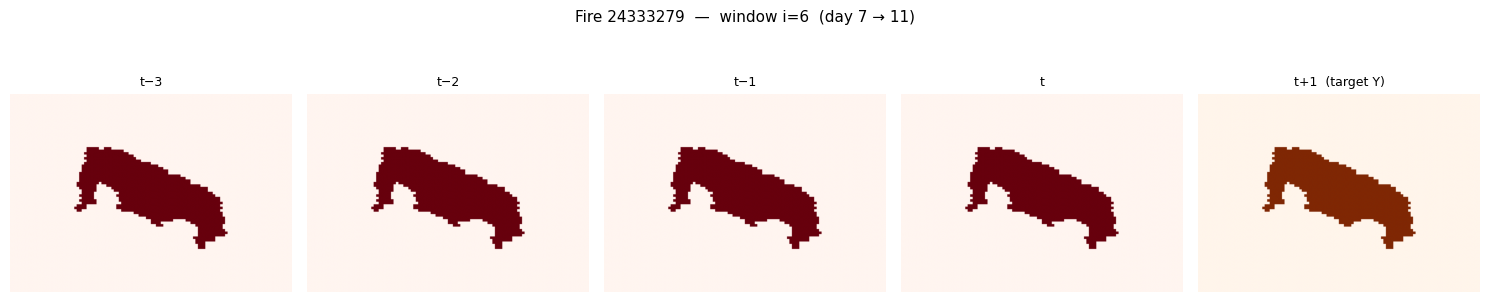

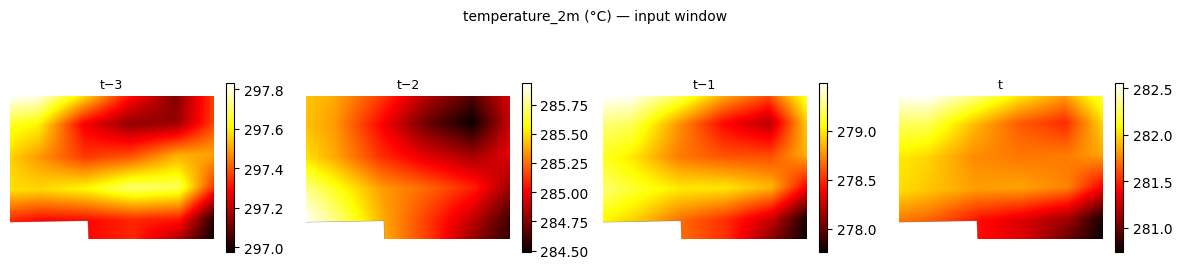

In [16]:
import matplotlib.pyplot as plt
import random

train_rows = [r for r in fire_results if r.get('success') and r.get('split') == 'train']
if not train_rows:
    print('No train fires to visualise.')
else:
    row  = random.choice(train_rows)
    data = np.load(TENSOR_DIR / row['split'] / f"{row['fire_id']}.npz")
    fm   = data['fire_masks']   # (N_days, H, W)
    wth  = data['weather']      # (N_days, 6, H, W)

    i = random.randint(0, row['n_samples'] - 1)
    X_masks = fm[i : i + WINDOW_SIZE]
    Y       = fm[i + WINDOW_SIZE]

    fig, axes = plt.subplots(1, WINDOW_SIZE + 1, figsize=(3 * (WINDOW_SIZE + 1), 3.5))
    fig.suptitle(f"Fire {row['fire_id']}  —  window i={i}  (day {i+1} → {i+WINDOW_SIZE+1})", fontsize=11)
    for d in range(WINDOW_SIZE):
        axes[d].imshow(X_masks[d], cmap='Reds', vmin=0, vmax=1)
        axes[d].set_title(f't−{WINDOW_SIZE-1-d}' if d < WINDOW_SIZE-1 else 't', fontsize=9)
        axes[d].axis('off')
    axes[WINDOW_SIZE].imshow(Y, cmap='Oranges', vmin=0, vmax=1)
    axes[WINDOW_SIZE].set_title('t+1  (target Y)', fontsize=9)
    axes[WINDOW_SIZE].axis('off')
    plt.tight_layout()
    plt.show()

    fig2, axes2 = plt.subplots(1, WINDOW_SIZE, figsize=(3 * WINDOW_SIZE, 3))
    fig2.suptitle('temperature_2m (°C) — input window', fontsize=10)
    for d in range(WINDOW_SIZE):
        im = axes2[d].imshow(wth[i + d, 0], cmap='hot')
        axes2[d].set_title(f't−{WINDOW_SIZE-1-d}' if d < WINDOW_SIZE-1 else 't', fontsize=9)
        axes2[d].axis('off')
        plt.colorbar(im, ax=axes2[d], shrink=0.7)
    plt.tight_layout()
    plt.show()

---
## Done — Phase 4 (temporal) complete ✓

Your Google Drive now contains:

```
data/
├── aligned_compressed/          ← Phase 3 input (now includes fire_mask_stacked)
├── tensors/
│   ├── train/
│   │   ├── <fire-id>.npz
│   │   ├── <fire-id>.npz
│   │   └── …
│   ├── val/
│   │   └── …
│   ├── test/
│   │   └── …
│   ├── sample_index.csv         ← maps every sample to fire_id, split, target_day
│   └── tensor_manifest.json     ← pipeline metadata and sample counts
└── splits/
    └── splits.json              ← fire-event-level train/val/test assignment
```

### Loading samples in the modelling notebook

```python
import numpy as np, pandas as pd

# Load one sample
data = np.load('tensors/train/<fire-id>.npz.npz')
fire_masks = data['fire_masks']   # (4, H, W)    uint8  — input fire history
weather    = data['weather']      # (4, 6, H, W) float32 — input weather
terrain    = data['terrain']      # (3, H, W)    float32 — static features
Y          = data['Y']            # (H, W)       uint8  — fire mask to predict

# Iterate all train samples via the index
index = pd.read_csv('tensors/sample_index.csv')
for row in index[index['split'] == 'train'].itertuples():
    data = np.load(row.sample_file)
    # … train your model …
```